# Lab 2 — Heat recovery with a countercurrent exchanger

Recover heat from a warm process stream to preheat water. Size an exchanger and predict how fouling changes its performance.

## Design workshop: run → compare → decide

All numerical methods, loops, tables and plots are supplied. You only change
values in cells marked **DESIGN SETTINGS** and write your engineering decisions.
In Colab, these settings also have parameter forms. The small worked examples
may be rerun after changing the named example values; their equations are supplied.
Run each analysis as provided; its implementation is collapsed where supported
and can be expanded if you are curious. No Python programming is assessed.

Work through the notebook in order. After changing an upstream setting, rerun
that section and every section below it so results stay consistent. Restore the
printed base values to reproduce the reference case. Keep at least one rejected
design and explain why you rejected it. Each analysis table is evidence for a
decision, not a complete answer on its own.

**Time budget (six hours):** setup and system prediction 30 min; balances and
feasibility 75 min; operating policy and checks 90 min; alternative designs
75 min; robustness and break 45 min; recommendation 45 min. The supplied
worked example belongs within the feasibility block, not an extra activity.

**Time budget: 6 hours, including a short break and submission.** Work in pairs,
but both partners must be able to explain every figure and calculation.
Prerequisites: material and energy balances, algebra, and reading tables and plots. No Python programming is required.
Use SI units unless explicitly stated. All case data are synthetic teaching values,
not measurements or validated equipment specifications.

Submit this notebook with outputs and a short engineering recommendation (300–500 words).
Include assumptions, a labelled flowsheet, equations, units, balance checks,
at least one sensitivity plot, and a discussion of model limitations.
Optional extensions are outside the six-hour budget.

## 1. Setup and prediction — 30 minutes
Before computing, sketch the apparatus and predict which parameter most strongly
affects its size or energy demand. Explain your reasoning in two sentences.

Locally, place `helpers.py` beside this notebook and install the root requirements.
In Colab, upload both files using the Files panel. Alternatively, after the repository
is published, set `HELPER_URL` below to the raw GitHub URL of this lab's `helpers.py`.
Use a commit SHA in the URL for reproducible teaching. Only download code from a
repository you trust. Each lab needs only its own helper file.

In [ ]:
from pathlib import Path
from urllib.request import urlretrieve

HELPER_URL = ""  # e.g. https://raw.githubusercontent.com/OWNER/REPO/COMMIT/lab_01_flow/helpers.py
if not Path("helpers.py").exists():
    if not HELPER_URL:
        raise FileNotFoundError("Upload this lab's helpers.py or set HELPER_URL, then rerun.")
    urlretrieve(HELPER_URL, "helpers.py")

import numpy as np
import matplotlib.pyplot as plt
import helpers as h

## See the whole system

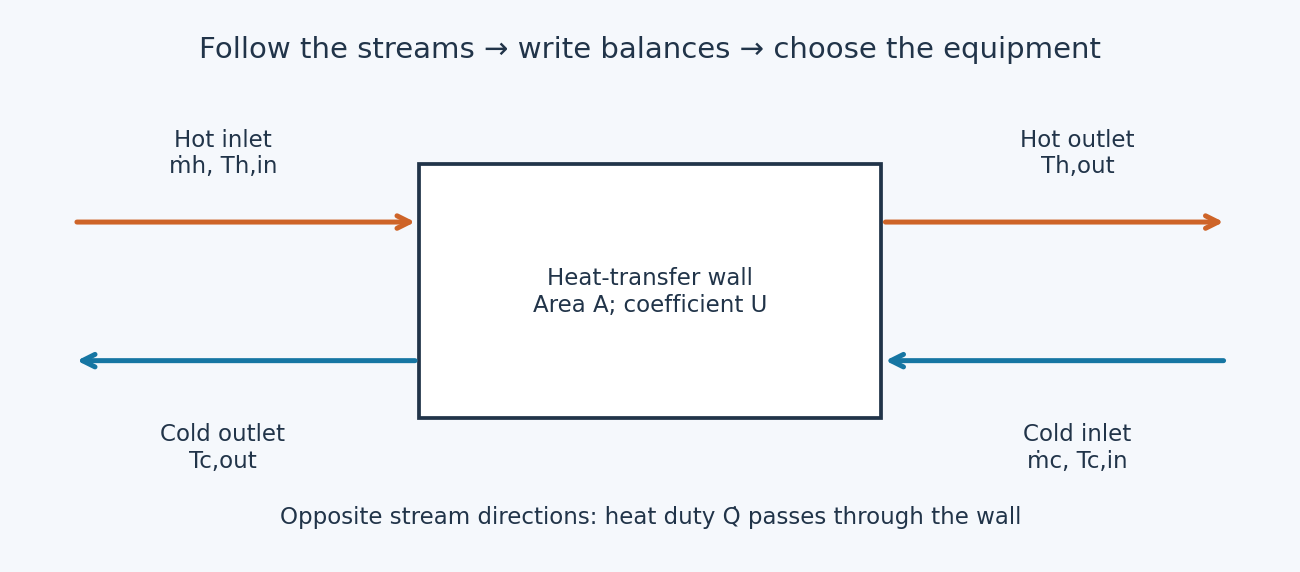

Schematic only: equipment sizes, heights and pipe lengths are not to scale.
Trace each stream with your finger. Identify what enters, what leaves, and where
energy is added or removed. Match the labels to the variables in the model below.

## Model and assumptions

Steady operation, no heat loss or phase change, constant heat capacities and overall
heat-transfer coefficient; ideal countercurrent flow, so the LMTD correction factor is 1.
$C_h=\dot m_hc_{p,h}$, $C_c=\dot m_cc_{p,c}$, and
$\dot Q=C_h(T_{h,in}-T_{h,out})=C_c(T_{c,out}-T_{c,in})$.
$\Delta T_1=T_{h,in}-T_{c,out}$, $\Delta T_2=T_{h,out}-T_{c,in}$.
$\Delta T_{lm}=(\Delta T_1-\Delta T_2)/\ln(\Delta T_1/\Delta T_2)$ and
$A=\dot Q/(U\Delta T_{lm})$. Both terminal differences must be positive.
For a fixed area use effectiveness–NTU to predict new outlets, rather than keeping
the design duty fixed. Resistances below refer to the same heat-transfer area.

### Worked example: heat a small cold-water stream
Trace the orange stream left to right and the blue stream right to left.
Use an easier target first: heat 0.5 kg/s of water from 15 to 35 °C using
1.0 kg/s of hot water entering at 70 °C. Both heat capacities are 4180 J/(kg K).
First calculate the duty, then use that same duty to calculate the hot outlet.
Only then calculate area. Expected results: 41.8 kW, 60 °C, and about 1.62 m².

In [ ]:
ex_Ch, ex_Cc = 1.0 * 4180, 0.5 * 4180  # W/K
ex_Thi, ex_Tci, ex_Tco = 70.0, 15.0, 35.0
ex_duty = ex_Cc * (ex_Tco - ex_Tci)
ex_Tho = ex_Thi - ex_duty / ex_Ch
ex_dt1, ex_dt2 = ex_Thi - ex_Tco, ex_Tho - ex_Tci
ex_lmtd = h.lmtd(ex_dt1, ex_dt2)
ex_area = ex_duty / (650.0 * ex_lmtd)
print(f"Duty = {ex_duty/1000:.1f} kW; hot outlet = {ex_Tho:.1f} °C")
print(f"Terminal differences = {ex_dt1:.1f}, {ex_dt2:.1f} K; LMTD = {ex_lmtd:.2f} K")
print(f"Required area = {ex_area:.2f} m²")
print("Energy-balance residual / W:", ex_Ch*(ex_Thi-ex_Tho)-ex_duty)

**Try a small change:** Copy the cell and raise the cold outlet target to 45 °C. Predict whether area rises or falls. Then try 75 °C: inspect both terminal differences and explain why this target fails before asking the helper to evaluate LMTD.

Spend about 20 minutes on this example within the model-development time below. Predict → run → explain. Then move to the main case.

### Main design case

The next cell defines the larger case used in the assessed tasks. Example variables use `ex_` so you can rerun them without changing this case.

In [ ]:
mh, mc = 1.2, 1.0  # kg/s
cph, cpc = 3800.0, 4180.0  # J/(kg K)
Thi, Tci, Tco_target = 85.0, 15.0, 55.0  # °C; differences are K
Ch, Cc = mh*cph, mc*cpc
U_clean = 650.0  # W/(m² K), assumed
duty = Cc * (Tco_target - Tci)
Tho = Thi - duty / Ch
delta_lm = h.lmtd(Thi-Tco_target, Tho-Tci)
area = duty / (U_clean * delta_lm)
print(f"Duty: {duty/1000:.1f} kW; hot outlet: {Tho:.2f} °C; area: {area:.2f} m²")

## 2. Check that the temperature target is feasible — 75 minutes

Run the supplied balance and temperature schematic. Check one duty
calculation with a calculator. Locate both terminal driving forces on the system
diagram. Is the target duty below the thermodynamic maximum? Explain why the
cold outlet may exceed the hot outlet without reversing local heat flow. Identify
the stream data you would measure to check this design in an operating plant.

**How to work:** Run the supplied analysis cell, read its table and plot,
then answer the decision questions in words. If this section has a settings cell,
change only those values and rerun this section and all following sections.
No numerical routines or plotting code need to be written. A failed constraint
is a result to discuss, not something to hide. Keep units with every reported value.

In [ ]:
#@title SUPPLIED ANALYSIS — run as provided; no edits needed
cold_duty = mc*cpc*(Tco_target-Tci)
independent_hot_out = Thi-cold_duty/(mh*cph)
dt1, dt2 = Thi-Tco_target, independent_hot_out-Tci
independent_lmtd = (dt1-dt2)/np.log(dt1/dt2)
independent_area = cold_duty/(U_clean*independent_lmtd)
qmax = min(Ch, Cc)*(Thi-Tci)
effectiveness = cold_duty/qmax
energy_residual = Ch*(Thi-independent_hot_out)-cold_duty
assert np.isclose(independent_area, area)
assert abs(energy_residual) < 1e-8
print(f"Duty = {cold_duty/1000:.3f} kW; hot outlet = {independent_hot_out:.4f} °C")
print(f"Area = {independent_area:.5f} m²; Qmax = {qmax/1000:.3f} kW; effectiveness = {effectiveness:.6f}")
print(f"Balance residual = {energy_residual:.3e} W; terminal differences = {dt1:.3f}, {dt2:.3f} K")
plt.figure(figsize=(7,4))
plt.plot([0,1], [Thi, independent_hot_out], 'o-', label='Hot stream →')
plt.plot([0,1], [Tco_target, Tci], 'o-', label='Cold stream ←')
plt.xticks([0,1], ['Hot inlet / cold outlet', 'Hot outlet / cold inlet'])
plt.ylabel('Temperature / °C'); plt.title('Terminal temperatures — schematic connections only')
plt.legend(); plt.grid(); plt.show()

**Your design decision — complete in words:**

1. **Prediction / requirement:** …
2. **Evidence:** Report at least two numbers from the table or plot, with units.
3. **Decision and tradeoff:** …
4. **What could change the decision?** State an assumption or missing measurement.

You are assessed on engineering reasoning, not on writing Python.

## 3. Review the thermal design checks — 90 minutes

Run the supplied effectiveness–NTU verification. Compare its outlet
temperatures with the LMTD design. Explain the zero-transfer and large-area
limits in physical terms. Do the agreement and limiting-case checks establish
that the real exchanger will work? Identify at least two assumptions that still
need confirmation. Choose whether this design is ready for thermal review,
hydraulic review or purchase, and justify that decision.

**How to work:** Run the supplied analysis cell, read its table and plot,
then answer the decision questions in words. If this section has a settings cell,
change only those values and rerun this section and all following sections.
No numerical routines or plotting code need to be written. A failed constraint
is a result to discuss, not something to hide. Keep units with every reported value.

In [ ]:
#@title SUPPLIED ANALYSIS — run as provided; no edits needed
def effectiveness_own(ntu, cr):
    if ntu < 0 or not 0 <= cr <= 1:
        raise ValueError("Require NTU >= 0 and 0 <= Cr <= 1")
    if abs(1-cr) < 1e-10:
        return ntu/(1+ntu)
    numerator = -np.expm1(-ntu*(1-cr))
    return numerator/((1-cr)+cr*numerator)

def predict_outlets(UA, hot_capacity=Ch, cold_capacity=Cc):
    cmin, cmax = min(hot_capacity, cold_capacity), max(hot_capacity, cold_capacity)
    eps = effectiveness_own(UA/cmin, cmin/cmax)
    q = eps*cmin*(Thi-Tci)
    return Thi-q/hot_capacity, Tci+q/cold_capacity, q

ntu, cr = U_clean*area/min(Ch,Cc), min(Ch,Cc)/max(Ch,Cc)
recovered_hot, recovered_cold, recovered_duty = predict_outlets(U_clean*area)
assert np.allclose([recovered_hot, recovered_cold, recovered_duty], [Tho,Tco_target,duty])
assert np.isclose(effectiveness_own(2,1), 2/3)
assert np.isclose(effectiveness_own(1e-9,.5), 1e-9, rtol=1e-6, atol=1e-15)
assert np.isclose(effectiveness_own(100,.5), 1)
assert np.isclose(effectiveness_own(0,.5), 0)
for test_ntu in [0, 1e-9, 1, 100]:
    for test_cr in [.5, 1.0]:
        assert np.isclose(effectiveness_own(test_ntu,test_cr), h.countercurrent_effectiveness(test_ntu,test_cr))
print(f"NTU = {ntu:.6f}; Cr = {cr:.6f}; hot outlet = {recovered_hot:.4f} °C; cold outlet = {recovered_cold:.4f} °C")
print("Zero, small/large NTU, equal-capacity and helper comparisons passed")

**Your design decision — complete in words:**

1. **Prediction / requirement:** …
2. **Evidence:** Report at least two numbers from the table or plot, with units.
3. **Decision and tradeoff:** …
4. **What could change the decision?** State an assumption or missing measurement.

You are assessed on engineering reasoning, not on writing Python.

## 4. Choose a fouling allowance and installed area — 75 minutes

Choose an added fouling resistance in the settings cell. Read the
fixed-area performance curves and compare a clean-sized unit with an enlarged
unit designed to meet the target at your chosen resistance. Report the added
area percentage. Would you specify the larger area or accept a lower outlet
temperature between cleanings? State the process requirement supporting your
choice. What happens when the enlarged exchanger is clean, and what control
action would be needed?

**How to work:** Run the supplied analysis cell, read its table and plot,
then answer the decision questions in words. If this section has a settings cell,
change only those values and rerun this section and all following sections.
No numerical routines or plotting code need to be written. A failed constraint
is a result to discuss, not something to hide. Keep units with every reported value.

In [ ]:
#@title DESIGN SETTINGS — edit values or use the Colab form
# m² K/W; choose between 0 and 0.001
design_R = 0.0006 #@param {type:"number"}

In [ ]:
#@title SUPPLIED ANALYSIS — run as provided; no edits needed
resistance = np.unique(np.r_[np.linspace(0,.001,60), .0006])
fouled_U = 1/(1/U_clean+resistance)
fixed_area_results = np.array([h.outlets(u*area, Ch, Cc, Thi, Tci) for u in fouled_U])
design_U = 1/(1/U_clean+design_R)
fouled_sized_area = duty/(design_U*delta_lm)
at_design = h.outlets(design_U*area, Ch,Cc,Thi,Tci)
enlarged_design = h.outlets(design_U*fouled_sized_area, Ch,Cc,Thi,Tci)
enlarged_clean = h.outlets(U_clean*fouled_sized_area, Ch,Cc,Thi,Tci)
assert np.isclose(enlarged_design[1],Tco_target)
print(f"At design fouling: U={design_U:.3f} W/(m² K)")
print(f"Clean-sized area={area:.4f} m²: Tco={at_design[1]:.4f} °C, duty={at_design[2]/1000:.3f} kW")
print(f"Fouling-sized area={fouled_sized_area:.4f} m²: Tco={enlarged_design[1]:.4f} °C")
print(f"When clean, enlarged unit gives Tco={enlarged_clean[1]:.4f} °C: allow for control")
fig, axes = plt.subplots(1,2,figsize=(11,4))
axes[0].plot(resistance*1e4, fixed_area_results[:,2]/1000)
axes[0].set_ylabel('Recovered duty / kW')
axes[1].plot(resistance*1e4, fixed_area_results[:,1])
axes[1].axhline(55,color='black',linestyle=':', label='Target'); axes[1].legend()
axes[1].set_ylabel('Cold outlet / °C')
for axis in axes:
    axis.set_xlabel('Added resistance / (10$^{-4}$ m² K W$^{-1}$)'); axis.grid()
plt.tight_layout(); plt.show()
print(f"Area increase: {(fouled_sized_area/area-1)*100:.1f}%")

**Your design decision — complete in words:**

1. **Prediction / requirement:** …
2. **Evidence:** Report at least two numbers from the table or plot, with units.
3. **Decision and tradeoff:** …
4. **What could change the decision?** State an assumption or missing measurement.

You are assessed on engineering reasoning, not on writing Python.

## 5. Define an operating envelope — 45 minutes

Take a 10-minute break. Use the supplied cold-flow sweep at fixed
chosen area and fouling allowance. Identify which tested flows meet the 55 °C
target, and select an operating flow or range. Explain the difference between
maximizing heat recovery and maximizing outlet temperature. What further
pressure-drop and pumping calculations must accompany your thermal decision?
State why the constant-U sweep is provisional.

**How to work:** Run the supplied analysis cell, read its table and plot,
then answer the decision questions in words. If this section has a settings cell,
change only those values and rerun this section and all following sections.
No numerical routines or plotting code need to be written. A failed constraint
is a result to discuss, not something to hide. Keep units with every reported value.

In [ ]:
#@title DESIGN SETTINGS — edit values or use the Colab form
# kg/s
cold_flow_low = 0.5 #@param {type:"number"}
# kg/s
cold_flow_high = 1.8 #@param {type:"number"}

In [ ]:
#@title SUPPLIED ANALYSIS — run as provided; no edits needed
cold_flows = np.unique(np.r_[np.linspace(cold_flow_low,cold_flow_high,60),mc])
# Chosen design: fouling-sized area, operated at design fouling resistance.
flow_results = np.array([h.outlets(design_U*fouled_sized_area,Ch,value*cpc,Thi,Tci)
                         for value in cold_flows])
fig, axes = plt.subplots(1,2,figsize=(11,4))
axes[0].plot(cold_flows,flow_results[:,1]); axes[0].set_ylabel('Cold outlet / °C')
axes[1].plot(cold_flows,flow_results[:,2]/1000); axes[1].set_ylabel('Recovered duty / kW')
for axis in axes:
    axis.set_xlabel('Cold mass flow / kg s$^{-1}$'); axis.grid()
plt.tight_layout(); plt.show()
for index in [0,-1]:
    print(f"mc={cold_flows[index]:.2f} kg/s: Tco={flow_results[index,1]:.3f} °C, duty={flow_results[index,2]/1000:.3f} kW")
assert np.allclose(Ch*(Thi-flow_results[:,0]), cold_flows*cpc*(flow_results[:,1]-Tci))
meets_target = flow_results[:,1] >= Tco_target-1e-8
if np.any(meets_target):
    qualifying = cold_flows[meets_target]
    print(f"Tested flows meeting target: {qualifying.min():.3f}–{qualifying.max():.3f} kg/s")
else:
    print("No tested flow meets the outlet-temperature target")

**Your design decision — complete in words:**

1. **Prediction / requirement:** …
2. **Evidence:** Report at least two numbers from the table or plot, with units.
3. **Decision and tradeoff:** …
4. **What could change the decision?** State an assumption or missing measurement.

You are assessed on engineering reasoning, not on writing Python.

## 6. Engineering recommendation and submission — 45 minutes
Choose a design and support it with numbers. State what would need measuring before
using it in practice. Check your balances and inspect every axis label and unit.
Restart the kernel and run all completed cells in order before submission.

**Peer check:** Ask your partner to explain one equation, one numerical check,
and one reason the model could fail. Record any revision this discussion prompted.

**Design-review checklist:** Does your selected design meet every stated
requirement? Include its operating margin, one rejected alternative and a
numerical reason for rejection. Distinguish a model verification check from
evidence that real equipment will perform as predicted. Identify the next
measurement or vendor datum needed. No new code is required for submission.

## Optional design-review extension

No coding is required. Would a low cold outlet necessarily prove fouling? Propose measurements that distinguish heat loss to the room from reduced UA.